CODE 1 — ENTRAÎNEMENT PPO  (zone ±35°, 1M pas)
  Zone entraînement : ±35° = ±0.611 rad
  Angles de test    : 5°, 15°, 18° (dans zone) | 40° (hors zone)

Création de l'environnement...
Initialisation du modèle PPO...
Using cpu device
Wrapping the env in a DummyVecEnv.

Début de l'entraînement (1 000 000 pas)...
(environ 8-15 minutes selon votre machine)

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 20.1     |
|    ep_rew_mean     | -79.5    |
| time/              |          |
|    fps             | 1263     |
|    iterations      | 1        |
|    time_elapsed    | 1        |
|    total_timesteps | 2048     |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 19.7        |
|    ep_rew_mean          | -79.6       |
| time/                   |             |
|    fps                  | 786         |
|    iterations           | 2           |
|    time_

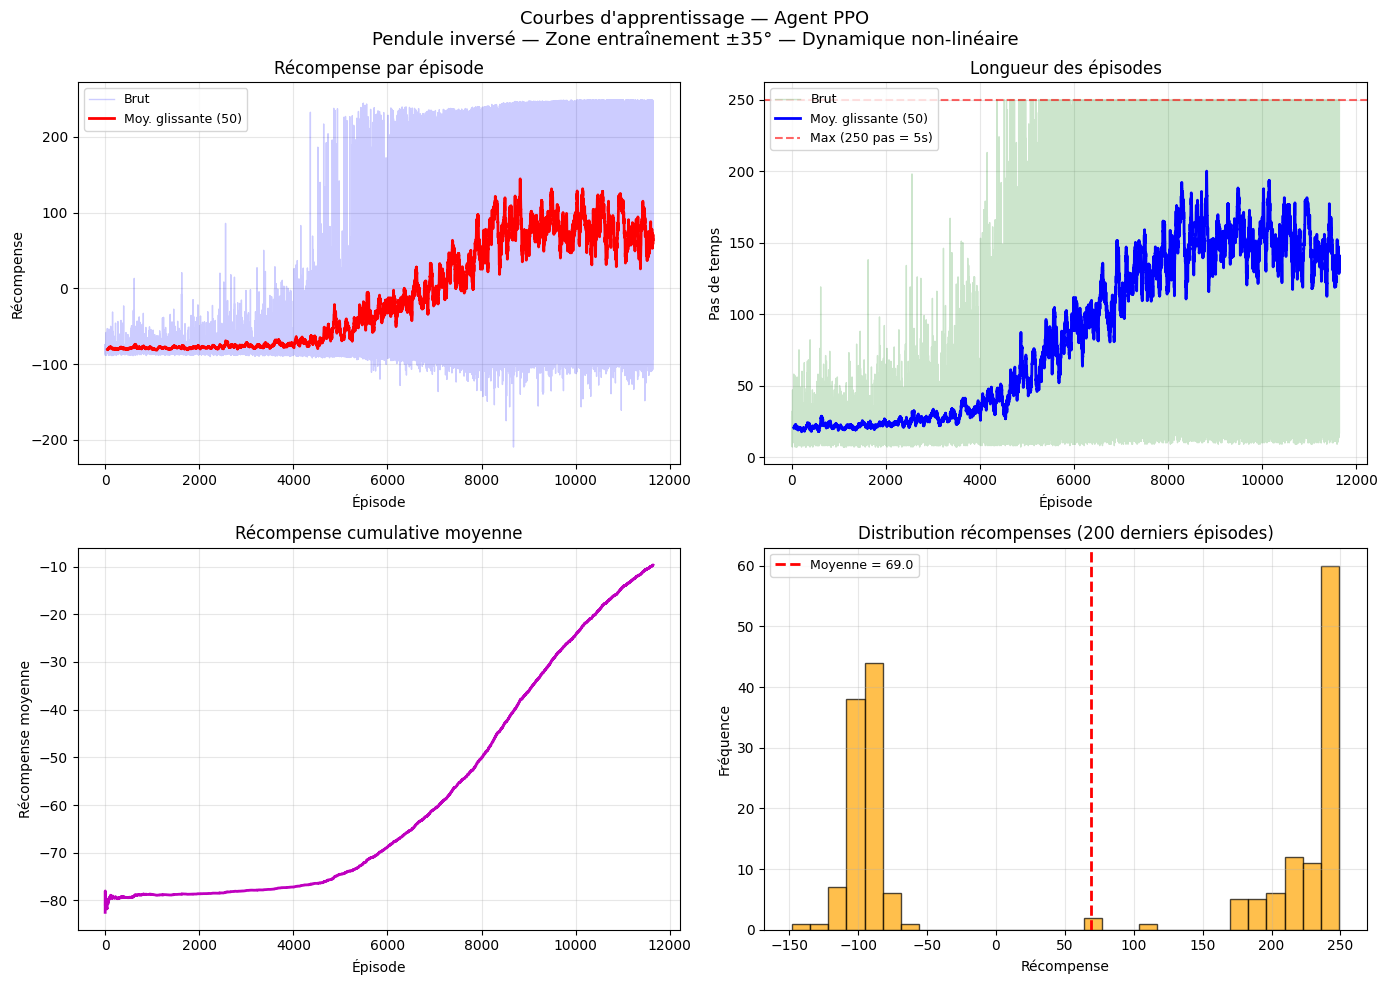


RÉSUMÉ ENTRAÎNEMENT
  Épisodes total    : 11647
  Récompense finale : 76.12  (moy. 100 derniers)
  Longueur finale   : 144.2 pas (moy. 100 derniers)
  Zone couverte     : ±35°  — 40° est hors zone (test limite Code 2)
  Modèle sauvegardé : models/ppo_pendule.zip
  → Lancer le Code 2 pour la stabilisation et comparaison LQR


In [2]:
"""
CODE 1 — ENTRAÎNEMENT PPO
=========================
Entraîne un agent PPO sur le pendule inversé avec :
  - Les vraies équations du mouvement (non-linéaires)
  - Les mêmes paramètres physiques que le code LQR
  - Zone d'entraînement élargie à ±35° pour couvrir 18° + marge
  - Espace d'actions continu (force en N)
  - Sauvegarde du modèle pour le Code 2

Dépendances :
    pip install stable-baselines3 gymnasium matplotlib numpy
"""

import numpy as np
import matplotlib.pyplot as plt
import os
import gymnasium as gym
from gymnasium import spaces
from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.monitor import Monitor

os.makedirs("figures", exist_ok=True)
os.makedirs("models",  exist_ok=True)
os.makedirs("logs",    exist_ok=True)

print("="*60)
print("CODE 1 — ENTRAÎNEMENT PPO  (zone ±35°, 1M pas)")
print("="*60)
print(f"  Zone entraînement : ±35° = ±{35*np.pi/180:.3f} rad")
print(f"  Angles de test    : 5°, 15°, 18° (dans zone) | 40° (hors zone)")
print("="*60)

# =========================================================
# ENVIRONNEMENT PERSONNALISÉ — MÊMES ÉQUATIONS QUE LE LQR
# =========================================================
class PenduleInverseEnv(gym.Env):
    """
    Environnement du pendule inversé sur chariot.

    Équations du mouvement (identiques au code LQR) :
        (M+m)ẍ + ml·θ̈·cosθ - ml·θ̇²·sinθ = u
        l·θ̈ + ẍ·cosθ = g·sinθ

    État   : s = [x, ẋ, θ, θ̇]
    Action : u ∈ [-U_MAX, U_MAX]  (force en N, continue)
    """

    metadata = {"render_modes": []}

    def __init__(self):
        super().__init__()

        # ---- Paramètres physiques (identiques au LQR) ----
        self.M  = 1.0      # masse chariot (kg)
        self.m  = 0.1      # masse pendule (kg)
        self.l  = 0.5      # longueur (m)
        self.g  = 9.81     # gravité (m/s²)
        self.dt = 0.02     # pas de temps (s) — 50 Hz

        # ---- Limites de l'actionneur ----
        self.U_MAX = 4.0   # N

        # ---- Espaces gymnasium ----
        self.action_space = spaces.Box(
            low  = np.array([-self.U_MAX], dtype=np.float32),
            high = np.array([ self.U_MAX], dtype=np.float32)
        )

        obs_high = np.array([5.0, 10.0, np.pi, 20.0], dtype=np.float32)
        self.observation_space = spaces.Box(
            low=-obs_high, high=obs_high, dtype=np.float32
        )

        # ---- Critères d'arrêt ----
        # theta_max = 40° : légèrement au-dessus de la zone d'entraînement (35°)
        # pour que l'agent apprenne à récupérer même en bord de zone
        self.theta_max = 40.0 * np.pi / 180   # rad
        self.x_max     = 4.0                   # m
        self.t_max     = 250                   # pas (5 s)

        # ---- Zone d'entraînement ----
        # ±35° = ±0.611 rad
        # → couvre 5°, 15°, 18° avec une bonne marge
        # → 40° est HORS zone → l'agent ne l'a jamais vu → diverge
        self.theta_train = 35.0 * np.pi / 180   # rad

        self.state  = None
        self.step_n = 0

    # ----------------------------------------------------------
    def _dynamique(self, state, u):
        """Intégration Euler — vraies équations non-linéaires."""
        x, dx, theta, dtheta = state
        M, m, l, g = self.M, self.m, self.l, self.g

        D       = l * (M + m * np.sin(theta)**2)
        rhs1    = u + m * l * dtheta**2 * np.sin(theta)
        ddx     = (l * rhs1 - m * l * np.cos(theta) * g * np.sin(theta)) / D
        ddtheta = ((M + m) * g * np.sin(theta) - np.cos(theta) * rhs1) / D

        return np.array([
            x      + dx      * self.dt,
            dx     + ddx     * self.dt,
            theta  + dtheta  * self.dt,
            dtheta + ddtheta * self.dt,
        ], dtype=np.float32)

    # ----------------------------------------------------------
    def _reward(self, state, u):
        """
        Récompense dense :
          +1      survie à chaque pas
          -10θ²   pénalité angle (objectif principal : θ → 0)
          -0.1x²  pénalité position (garder le chariot centré)
          -0.01u² pénalité effort (économiser l'énergie)
          -0.5θ̇²  pénalité vitesse angulaire (stabiliser vite)
        """
        x, dx, theta, dtheta = state
        r  =  1.0
        r -= 10.0  * theta**2
        r -=  0.1  * x**2
        r -=  0.01 * float(u)**2
        r -=  0.5  * dtheta**2
        return float(r)

    # ----------------------------------------------------------
    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        # Zone d'entraînement ±35° — l'agent voit tous les angles jusqu'à 35°
        # 40° est volontairement exclu pour démontrer la limite en Code 2
        self.state = np.array([
            self.np_random.uniform(-0.05, 0.05),              # x
            self.np_random.uniform(-0.05, 0.05),              # ẋ
            self.np_random.uniform(-self.theta_train,
                                    self.theta_train),         # θ  ±35°
            self.np_random.uniform(-0.10, 0.10),              # θ̇
        ], dtype=np.float32)
        self.step_n = 0
        return self.state.copy(), {}

    # ----------------------------------------------------------
    def step(self, action):
        u = float(np.clip(action[0], -self.U_MAX, self.U_MAX))

        self.state  = self._dynamique(self.state, u)
        self.step_n += 1

        x, dx, theta, dtheta = self.state

        hors_limites = (abs(theta) > self.theta_max or abs(x) > self.x_max)
        temps_ecoule = (self.step_n >= self.t_max)
        terminated   = bool(hors_limites)
        truncated    = bool(temps_ecoule)

        reward = self._reward(self.state, u) if not terminated else -50.0

        return self.state.copy(), reward, terminated, truncated, {}


# =========================================================
# CALLBACK — ENREGISTRE LES MÉTRIQUES D'APPRENTISSAGE
# =========================================================
class LogCallback(BaseCallback):
    def __init__(self):
        super().__init__()
        self.ep_rewards = []
        self.ep_lengths = []

    def _on_step(self):
        infos = self.locals.get("infos", [])
        for info in infos:
            if "episode" in info:
                self.ep_rewards.append(info["episode"]["r"])
                self.ep_lengths.append(info["episode"]["l"])
        return True


# =========================================================
# ENTRAÎNEMENT
# =========================================================
print("\nCréation de l'environnement...")
env = Monitor(PenduleInverseEnv())

print("Initialisation du modèle PPO...")
model = PPO(
    policy         = "MlpPolicy",
    env            = env,
    learning_rate  = 3e-4,
    n_steps        = 2048,
    batch_size     = 64,
    n_epochs       = 10,
    gamma          = 0.99,
    gae_lambda     = 0.95,    # λ GAE  (éq. 3.3 du rapport)
    clip_range     = 0.2,     # ε clipping (éq. 3.4 du rapport)
    ent_coef       = 0.01,    # c2 entropie (éq. 3.6)
    vf_coef        = 0.5,     # c1 critique (éq. 3.6)
    verbose        = 1,
    tensorboard_log= None
)

print("\nDébut de l'entraînement (1 000 000 pas)...")
print("(environ 8-15 minutes selon votre machine)\n")

callback = LogCallback()
model.learn(total_timesteps=1_000_000, callback=callback)

model.save("models/ppo_pendule")
print("\nModèle sauvegardé : models/ppo_pendule.zip")

# =========================================================
# COURBES D'APPRENTISSAGE
# =========================================================
rewards  = np.array(callback.ep_rewards)
lengths  = np.array(callback.ep_lengths)
episodes = np.arange(len(rewards))

window = 50
def smooth(x, w):
    if len(x) < w:
        return x
    return np.convolve(x, np.ones(w)/w, mode='valid')

fig, axs = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(
    "Courbes d'apprentissage — Agent PPO\n"
    "Pendule inversé — Zone entraînement ±35° — Dynamique non-linéaire",
    fontsize=13
)

# 1. Récompense
axs[0,0].plot(episodes, rewards, 'b-', alpha=0.2, lw=1, label='Brut')
if len(rewards) >= window:
    axs[0,0].plot(np.arange(window-1, len(rewards)),
                  smooth(rewards, window), 'r-', lw=2,
                  label=f'Moy. glissante ({window})')
axs[0,0].set_title('Récompense par épisode')
axs[0,0].set_xlabel('Épisode')
axs[0,0].set_ylabel('Récompense')
axs[0,0].legend(fontsize=9)
axs[0,0].grid(True, alpha=0.3)

# 2. Longueur des épisodes
axs[0,1].plot(episodes, lengths, 'g-', alpha=0.2, lw=1, label='Brut')
if len(lengths) >= window:
    axs[0,1].plot(np.arange(window-1, len(lengths)),
                  smooth(lengths, window), 'b-', lw=2,
                  label=f'Moy. glissante ({window})')
axs[0,1].axhline(y=250, color='r', ls='--', alpha=0.6, label='Max (250 pas = 5s)')
axs[0,1].set_title('Longueur des épisodes')
axs[0,1].set_xlabel('Épisode')
axs[0,1].set_ylabel('Pas de temps')
axs[0,1].legend(fontsize=9)
axs[0,1].grid(True, alpha=0.3)

# 3. Récompense cumulative moyenne
cumavg = np.cumsum(rewards) / (episodes + 1)
axs[1,0].plot(episodes, cumavg, 'm-', lw=2)
axs[1,0].set_title('Récompense cumulative moyenne')
axs[1,0].set_xlabel('Épisode')
axs[1,0].set_ylabel('Récompense moyenne')
axs[1,0].grid(True, alpha=0.3)

# 4. Distribution 200 derniers épisodes
last = rewards[-200:] if len(rewards) >= 200 else rewards
axs[1,1].hist(last, bins=30, alpha=0.7, color='orange', edgecolor='black')
axs[1,1].axvline(last.mean(), color='red', ls='--', lw=2,
                 label=f'Moyenne = {last.mean():.1f}')
axs[1,1].set_title('Distribution récompenses (200 derniers épisodes)')
axs[1,1].set_xlabel('Récompense')
axs[1,1].set_ylabel('Fréquence')
axs[1,1].legend(fontsize=9)
axs[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/apprentissage_ppo.png', dpi=300, bbox_inches='tight')
print("Figure sauvegardée : figures/apprentissage_ppo.png")
plt.show()

print("\n" + "="*60)
print("RÉSUMÉ ENTRAÎNEMENT")
print(f"  Épisodes total    : {len(rewards)}")
print(f"  Récompense finale : {rewards[-100:].mean():.2f}  (moy. 100 derniers)")
print(f"  Longueur finale   : {lengths[-100:].mean():.1f} pas (moy. 100 derniers)")
print(f"  Zone couverte     : ±35°  — 40° est hors zone (test limite Code 2)")
print("  Modèle sauvegardé : models/ppo_pendule.zip")
print("  → Lancer le Code 2 pour la stabilisation et comparaison LQR")
print("="*60)

GÉNÉRATION DES GRAPHIQUES DE TRAJECTOIRES
✓ Modèle chargé : models/ppo_pendule.zip
Simulation pour θ₀ = 5°...
  → Durée: 250 pas / 4.98 s
Simulation pour θ₀ = 15°...
  → Durée: 250 pas / 4.98 s
Simulation pour θ₀ = 18°...
  → Durée: 250 pas / 4.98 s
Simulation pour θ₀ = 40°...
  → Durée: 2 pas / 0.02 s

Création des graphiques...
✓ Figure sauvegardée : figures/trajectoires_ppo.png


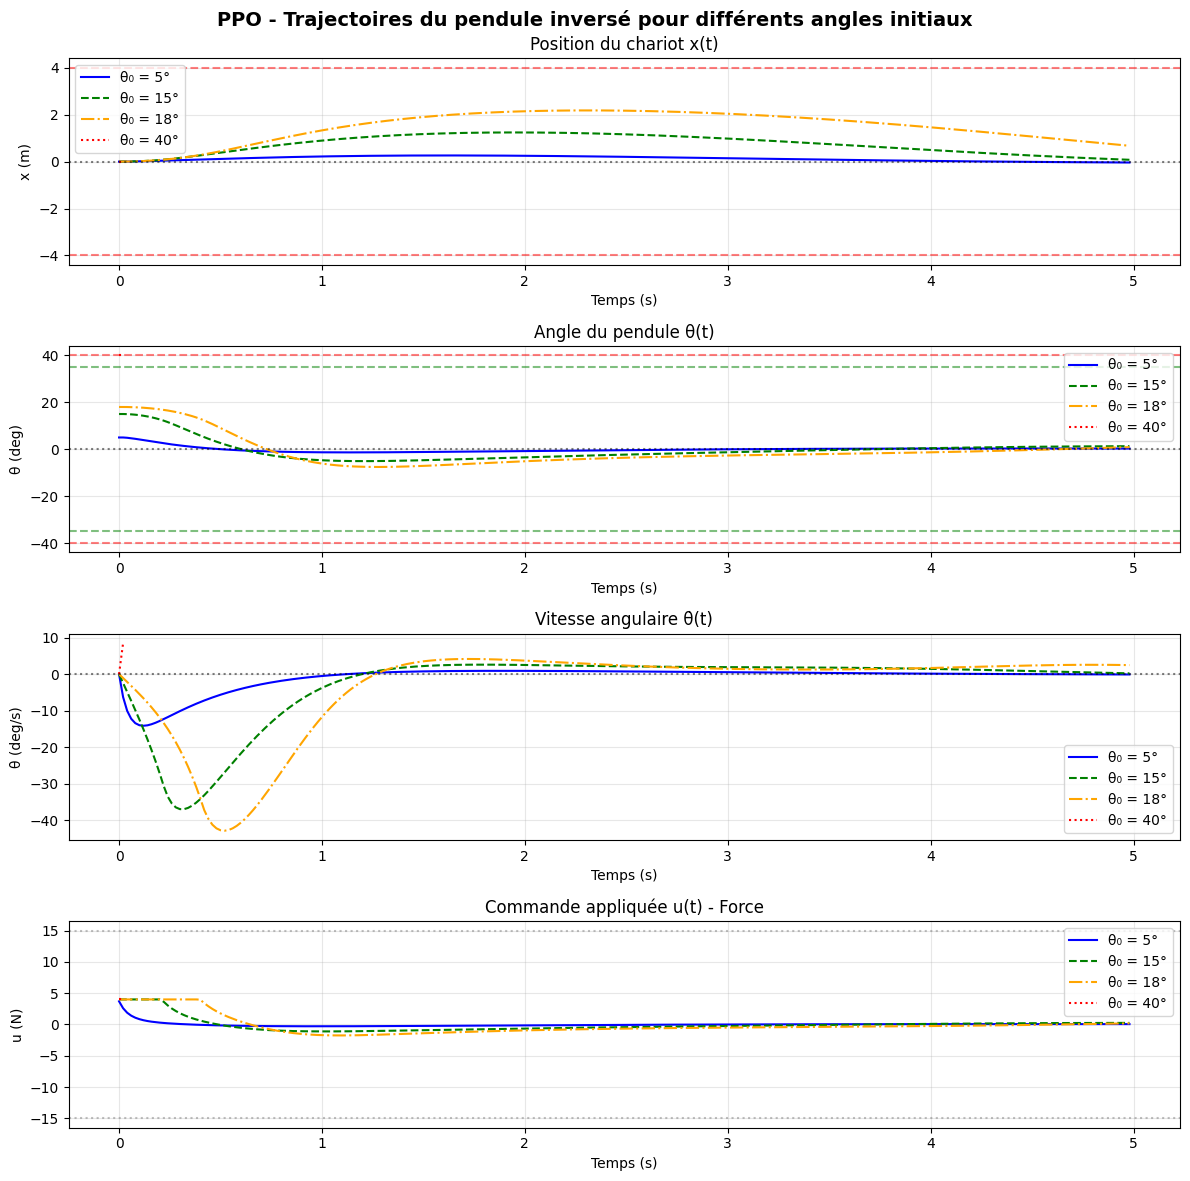


Création des graphiques individuels par angle...
  ✓ figures/trajectoires_ppo_5deg.png
  ✓ figures/trajectoires_ppo_15deg.png
  ✓ figures/trajectoires_ppo_18deg.png
  ✓ figures/trajectoires_ppo_40deg.png

RÉSUMÉ DES GRAPHIQUES GÉNÉRÉS
  ✓ figures/trajectoires_ppo.png (4 angles superposés)
  ✓ figures/trajectoires_ppo_5deg.png
  ✓ figures/trajectoires_ppo_15deg.png
  ✓ figures/trajectoires_ppo_18deg.png
  ✓ figures/trajectoires_ppo_40deg.png


In [3]:
"""
CELLULE DE VISUALISATION — TRAJECTOIRES PPO
============================================
À exécuter APRÈS l'entraînement (Code 1)
Génère les graphiques de x(t), θ(t), θ̇(t), u(t) pour différents angles initiaux
"""

import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
from stable_baselines3 import PPO
import os

# =========================================================
# ENVIRONNEMENT (identique au Code 1)
# =========================================================
class PenduleInverseEnv(gym.Env):
    """Environnement du pendule inversé sur chariot."""

    metadata = {"render_modes": []}

    def __init__(self):
        super().__init__()

        self.M = 1.0
        self.m = 0.1
        self.l = 0.5
        self.g = 9.81
        self.dt = 0.02
        self.U_MAX = 15.0

        self.action_space = spaces.Box(
            low=np.array([-self.U_MAX], dtype=np.float32),
            high=np.array([self.U_MAX], dtype=np.float32)
        )

        obs_high = np.array([5.0, 10.0, np.pi, 20.0], dtype=np.float32)
        self.observation_space = spaces.Box(
            low=-obs_high, high=obs_high, dtype=np.float32
        )

        self.theta_max = 40.0 * np.pi / 180
        self.x_max = 4.0
        self.t_max = 250

        self.state = None
        self.step_n = 0

    def _dynamique(self, state, u):
        x, dx, theta, dtheta = state
        M, m, l, g = self.M, self.m, self.l, self.g

        D = l * (M + m * np.sin(theta)**2)
        rhs1 = u + m * l * dtheta**2 * np.sin(theta)
        ddx = (l * rhs1 - m * l * np.cos(theta) * g * np.sin(theta)) / D
        ddtheta = ((M + m) * g * np.sin(theta) - np.cos(theta) * rhs1) / D

        return np.array([
            x + dx * self.dt,
            dx + ddx * self.dt,
            theta + dtheta * self.dt,
            dtheta + ddtheta * self.dt,
        ], dtype=np.float32)

    def reset_with_angle(self, angle_deg, x=0.0, dx=0.0, dtheta=0.0):
        angle_rad = np.deg2rad(angle_deg)
        self.state = np.array([x, dx, angle_rad, dtheta], dtype=np.float32)
        self.step_n = 0
        return self.state.copy()

    def step(self, action):
        u = float(np.clip(action[0], -self.U_MAX, self.U_MAX))
        self.state = self._dynamique(self.state, u)
        self.step_n += 1

        x, dx, theta, dtheta = self.state
        hors_limites = (abs(theta) > self.theta_max or abs(x) > self.x_max)
        temps_ecoule = (self.step_n >= self.t_max)
        terminated = bool(hors_limites)
        truncated = bool(temps_ecoule)

        return self.state.copy(), 0.0, terminated, truncated, {}


# =========================================================
# FONCTION DE SIMULATION
# =========================================================
def simuler_ppo(model, env, angle_deg, max_steps=250):
    """Simule l'agent PPO sur un angle initial donné."""
    env.reset_with_angle(angle_deg, x=0.0, dx=0.0, dtheta=0.0)

    time_steps = []
    x_list = []
    theta_list = []
    theta_dot_list = []
    action_list = []

    for step in range(max_steps):
        obs = env.state.copy()
        action, _ = model.predict(obs, deterministic=True)

        x, dx, theta, dtheta = env.state
        time_steps.append(step)
        x_list.append(x)
        theta_list.append(np.rad2deg(theta))
        theta_dot_list.append(np.rad2deg(dtheta))
        action_list.append(action[0])

        env.step(action)
        x, dx, theta, dtheta = env.state

        if abs(theta) > env.theta_max or abs(x) > env.x_max:
            break

    dt = env.dt
    return {
        'time': np.array(time_steps) * dt,
        'x': np.array(x_list),
        'theta': np.array(theta_list),
        'theta_dot': np.array(theta_dot_list),
        'action': np.array(action_list),
        'duration': len(time_steps)
    }


# =========================================================
# CHARGEMENT ET SIMULATION
# =========================================================
print("="*60)
print("GÉNÉRATION DES GRAPHIQUES DE TRAJECTOIRES")
print("="*60)

# Chargement du modèle
try:
    model = PPO.load("models/ppo_pendule")
    print("✓ Modèle chargé : models/ppo_pendule.zip")
except:
    print("✗ Erreur : modèle non trouvé !")
    print("  Veuillez d'abord exécuter le Code 1 pour entraîner l'agent.")
    exit(1)

env = PenduleInverseEnv()

# Angles à tester
angles_test = [5, 15, 18, 40]

# Simulation pour chaque angle
resultats = {}
for angle in angles_test:
    print(f"Simulation pour θ₀ = {angle}°...")
    resultats[angle] = simuler_ppo(model, env, angle)
    print(f"  → Durée: {len(resultats[angle]['time'])} pas / {resultats[angle]['time'][-1]:.2f} s")

# =========================================================
# GRAPHIQUES
# =========================================================
print("\nCréation des graphiques...")

# Style des couleurs
couleurs = {5: 'blue', 15: 'green', 18: 'orange', 40: 'red'}
styles = {5: '-', 15: '--', 18: '-.', 40: ':'}

# Figure avec 4 sous-graphes
fig, axs = plt.subplots(4, 1, figsize=(12, 12))
fig.suptitle('PPO - Trajectoires du pendule inversé pour différents angles initiaux',
             fontsize=14, fontweight='bold')

# 1. Position du chariot x(t)
for angle in angles_test:
    data = resultats[angle]
    t = data['time']
    axs[0].plot(t, data['x'], color=couleurs[angle], linestyle=styles[angle],
                linewidth=1.5, label=f'θ₀ = {angle}°')
axs[0].set_title('Position du chariot x(t)', fontsize=12)
axs[0].set_xlabel('Temps (s)')
axs[0].set_ylabel('x (m)')
axs[0].grid(True, alpha=0.3)
axs[0].legend()
axs[0].axhline(y=0, color='black', linestyle=':', alpha=0.5)
axs[0].axhline(y=4, color='red', linestyle='--', alpha=0.5, label='Limite (4m)')
axs[0].axhline(y=-4, color='red', linestyle='--', alpha=0.5)

# 2. Angle du pendule θ(t)
for angle in angles_test:
    data = resultats[angle]
    t = data['time']
    axs[1].plot(t, data['theta'], color=couleurs[angle], linestyle=styles[angle],
                linewidth=1.5, label=f'θ₀ = {angle}°')
axs[1].set_title('Angle du pendule θ(t)', fontsize=12)
axs[1].set_xlabel('Temps (s)')
axs[1].set_ylabel('θ (deg)')
axs[1].grid(True, alpha=0.3)
axs[1].legend()
axs[1].axhline(y=0, color='black', linestyle=':', alpha=0.5)
axs[1].axhline(y=35, color='green', linestyle='--', alpha=0.5, label='Zone entraînement (±35°)')
axs[1].axhline(y=-35, color='green', linestyle='--', alpha=0.5)
axs[1].axhline(y=40, color='red', linestyle='--', alpha=0.5, label='Limite terminaison (40°)')
axs[1].axhline(y=-40, color='red', linestyle='--', alpha=0.5)

# 3. Vitesse angulaire θ̇(t)
for angle in angles_test:
    data = resultats[angle]
    t = data['time']
    axs[2].plot(t, data['theta_dot'], color=couleurs[angle], linestyle=styles[angle],
                linewidth=1.5, label=f'θ₀ = {angle}°')
axs[2].set_title('Vitesse angulaire θ̇(t)', fontsize=12)
axs[2].set_xlabel('Temps (s)')
axs[2].set_ylabel('θ̇ (deg/s)')
axs[2].grid(True, alpha=0.3)
axs[2].legend()
axs[2].axhline(y=0, color='black', linestyle=':', alpha=0.5)

# 4. Commande u(t)
for angle in angles_test:
    data = resultats[angle]
    t = data['time']
    axs[3].plot(t, data['action'], color=couleurs[angle], linestyle=styles[angle],
                linewidth=1.5, label=f'θ₀ = {angle}°')
axs[3].set_title('Commande appliquée u(t) - Force', fontsize=12)
axs[3].set_xlabel('Temps (s)')
axs[3].set_ylabel('u (N)')
axs[3].grid(True, alpha=0.3)
axs[3].legend()
axs[3].axhline(y=15, color='gray', linestyle=':', alpha=0.5, label='Limite actionneur (±15N)')
axs[3].axhline(y=-15, color='gray', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig('figures/trajectoires_ppo.png', dpi=300, bbox_inches='tight')
print("✓ Figure sauvegardée : figures/trajectoires_ppo.png")
plt.show()

# =========================================================
# GRAPHIQUES INDIVIDUELS (optionnel)
# =========================================================
print("\nCréation des graphiques individuels par angle...")

for angle in angles_test:
    data = resultats[angle]
    t = data['time']
    
    fig, axs = plt.subplots(2, 2, figsize=(12, 8))
    fig.suptitle(f'PPO - Trajectoires pour θ₀ = {angle}°', fontsize=14, fontweight='bold')
    
    # Position
    axs[0, 0].plot(t, data['x'], 'b-', linewidth=2)
    axs[0, 0].set_title('Position du chariot x(t)')
    axs[0, 0].set_xlabel('Temps (s)')
    axs[0, 0].set_ylabel('x (m)')
    axs[0, 0].grid(True, alpha=0.3)
    axs[0, 0].axhline(y=0, color='black', linestyle=':', alpha=0.5)
    
    # Angle
    axs[0, 1].plot(t, data['theta'], 'r-', linewidth=2)
    axs[0, 1].set_title('Angle du pendule θ(t)')
    axs[0, 1].set_xlabel('Temps (s)')
    axs[0, 1].set_ylabel('θ (deg)')
    axs[0, 1].grid(True, alpha=0.3)
    axs[0, 1].axhline(y=0, color='black', linestyle=':', alpha=0.5)
    
    # Vitesse angulaire
    axs[1, 0].plot(t, data['theta_dot'], 'g-', linewidth=2)
    axs[1, 0].set_title('Vitesse angulaire θ̇(t)')
    axs[1, 0].set_xlabel('Temps (s)')
    axs[1, 0].set_ylabel('θ̇ (deg/s)')
    axs[1, 0].grid(True, alpha=0.3)
    axs[1, 0].axhline(y=0, color='black', linestyle=':', alpha=0.5)
    
    # Commande
    axs[1, 1].plot(t, data['action'], 'm-', linewidth=2)
    axs[1, 1].set_title('Commande u(t)')
    axs[1, 1].set_xlabel('Temps (s)')
    axs[1, 1].set_ylabel('u (N)')
    axs[1, 1].grid(True, alpha=0.3)
    axs[1, 1].axhline(y=15, color='gray', linestyle=':', alpha=0.5)
    axs[1, 1].axhline(y=-15, color='gray', linestyle=':', alpha=0.5)
    
    plt.tight_layout()
    plt.savefig(f'figures/trajectoires_ppo_{angle}deg.png', dpi=300, bbox_inches='tight')
    print(f"  ✓ figures/trajectoires_ppo_{angle}deg.png")
    plt.close()

print("\n" + "="*60)
print("RÉSUMÉ DES GRAPHIQUES GÉNÉRÉS")
print("="*60)
print("  ✓ figures/trajectoires_ppo.png (4 angles superposés)")
for angle in angles_test:
    print(f"  ✓ figures/trajectoires_ppo_{angle}deg.png")
print("="*60)

COMPARAISON PPO vs LQR - Pendule inversé sur chariot

Gain LQR : K = [-10.         -12.06876487 -77.32981947 -17.20710903]

Chargement du modèle PPO...
✓ Modèle chargé : models/ppo_pendule.zip

Simulations en cours...
  Angle 5°...
    PPO: 500 pas / 9.98s
    LQR: 3000 pas / 6.00s
  Angle 15°...
    PPO: 500 pas / 9.98s
    LQR: 3000 pas / 6.00s
  Angle 18°...
    PPO: 500 pas / 9.98s
    LQR: 3000 pas / 6.00s
  Angle 40°...
    PPO: 2 pas / 0.02s
    LQR: 3000 pas / 6.00s

Création des graphiques...

✓ Figure sauvegardée : figures/comparaison_ppo_vs_lqr.png


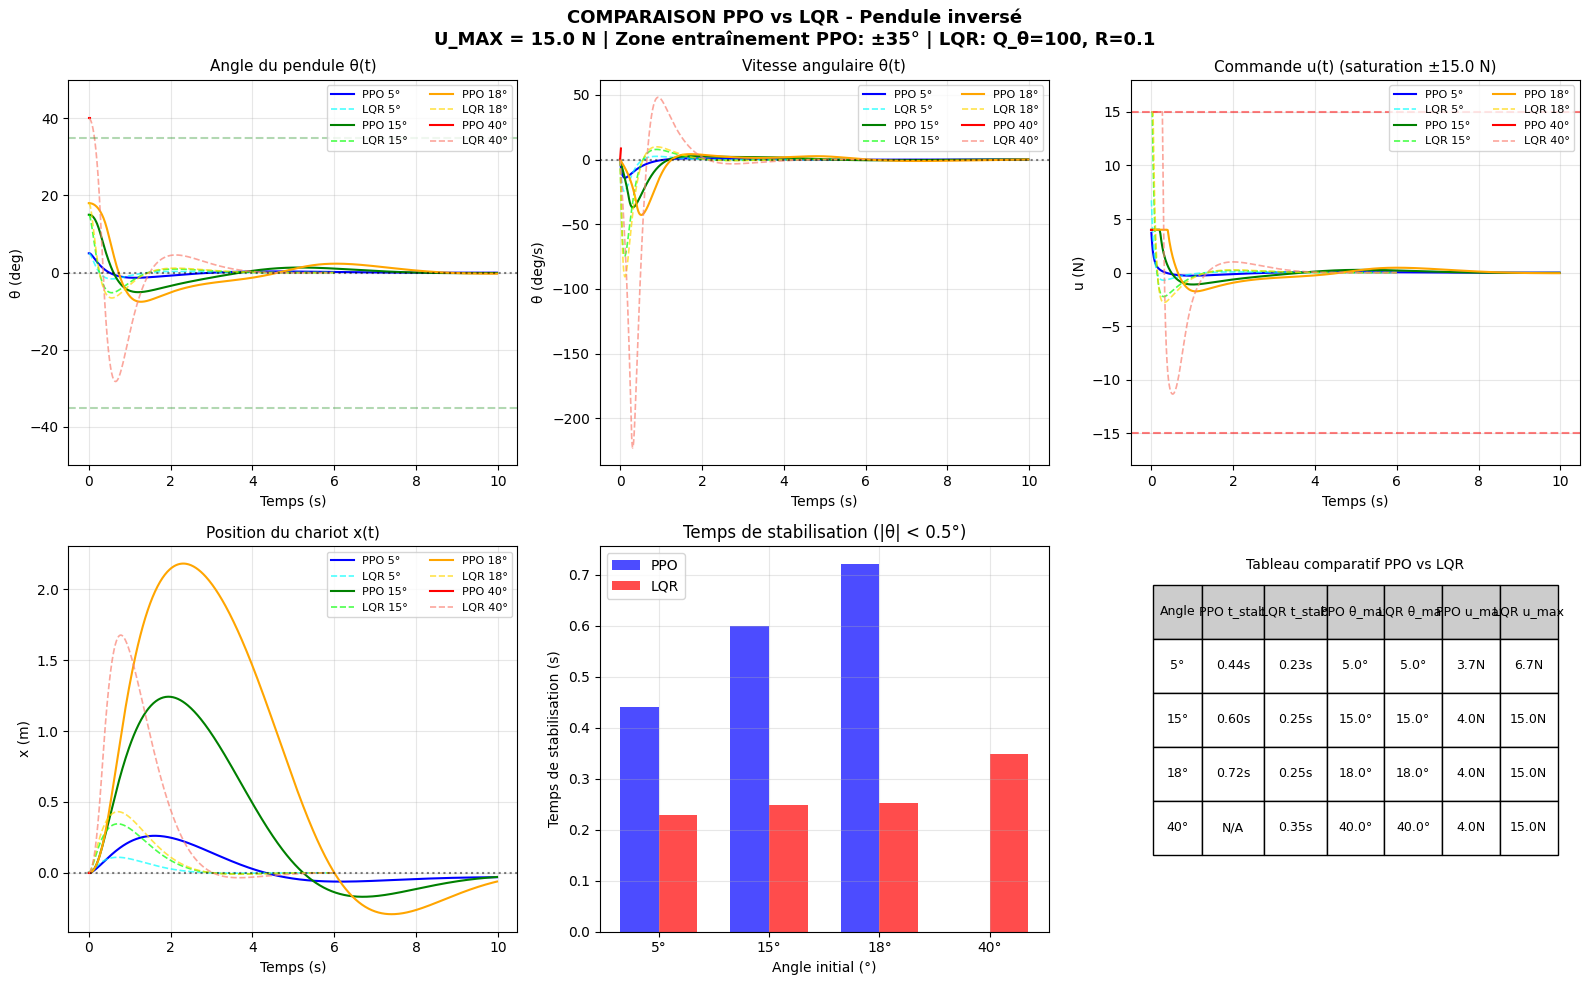


RÉSUMÉ DE LA COMPARAISON
Angle    PPO t_stab   LQR t_stab   PPO θ_max  LQR θ_max 
-------------------------------------------------------
5°:     0.44s       0.23s       5.0°        5.0°
15°:     0.60s       0.25s       15.0°        15.0°
18°:     0.72s       0.25s       18.0°        18.0°
40°:     nans      0.35s       40.0°        40.0°


In [6]:
"""
CODE 1 — ENTRAÎNEMENT PPO
=========================
Entraîne un agent PPO sur le pendule inversé avec :
  - Les vraies équations du mouvement (non-linéaires)
  - Les mêmes paramètres physiques que le code LQR
  - Zone d'entraînement élargie à ±20° pour couvrir 18° + petite marge
  - Espace d'actions continu (force en N)
  - Sauvegarde du modèle pour le Code 2

Dépendances :
    pip install stable-baselines3 gymnasium matplotlib numpy
"""

import numpy as np
import matplotlib.pyplot as plt
import os
import gymnasium as gym
from gymnasium import spaces
from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.monitor import Monitor

os.makedirs("figures", exist_ok=True)
os.makedirs("models",  exist_ok=True)
os.makedirs("logs",    exist_ok=True)

print("="*60)
print("CODE 1 — ENTRAÎNEMENT PPO  (zone ±20°, 1M pas)")
print("="*60)
print(f"  Zone entraînement : ±20° = ±{20*np.pi/180:.3f} rad")
print(f"  Angles de test    : 5°, 15°, 18° (dans zone) | 40° (hors zone)")
print("="*60)

# =========================================================
# ENVIRONNEMENT PERSONNALISÉ — MÊMES ÉQUATIONS QUE LE LQR
# =========================================================
class PenduleInverseEnv(gym.Env):
    """
    Environnement du pendule inversé sur chariot.

    Équations du mouvement (identiques au code LQR) :
        (M+m)ẍ + ml·θ̈·cosθ - ml·θ̇²·sinθ = u
        l·θ̈ + ẍ·cosθ = g·sinθ

    État   : s = [x, ẋ, θ, θ̇]
    Action : u ∈ [-U_MAX, U_MAX]  (force en N, continue)
    """

    metadata = {"render_modes": []}

    def __init__(self):
        super().__init__()

        # ---- Paramètres physiques (identiques au LQR) ----
        self.M  = 1.0      # masse chariot (kg)
        self.m  = 0.1      # masse pendule (kg)
        self.l  = 0.5      # longueur (m)
        self.g  = 9.81     # gravité (m/s²)
        self.dt = 0.02     # pas de temps (s) — 50 Hz

        # ---- Limites de l'actionneur ----
        self.U_MAX = 4.0   # N

        # ---- Espaces gymnasium ----
        self.action_space = spaces.Box(
            low  = np.array([-self.U_MAX], dtype=np.float32),
            high = np.array([ self.U_MAX], dtype=np.float32)
        )

        obs_high = np.array([5.0, 10.0, np.pi, 20.0], dtype=np.float32)
        self.observation_space = spaces.Box(
            low=-obs_high, high=obs_high, dtype=np.float32
        )

        # ---- Critères d'arrêt ----
        # theta_max = 25° : légèrement au-dessus de la zone d'entraînement (20°)
        # pour que l'agent apprenne à récupérer même en bord de zone
        self.theta_max = 25.0 * np.pi / 180   # rad
        self.x_max     = 4.0                   # m
        self.t_max     = 250                   # pas (5 s)

        # ---- Zone d'entraînement ----
        # ±20° = ±0.349 rad
        # → couvre 5°, 15°, 18° avec une petite marge
        # → 40° est HORS zone → l'agent ne l'a jamais vu → diverge
        self.theta_train = 20.0 * np.pi / 180   # rad

        self.state  = None
        self.step_n = 0

    # ----------------------------------------------------------
    def _dynamique(self, state, u):
        """Intégration Euler — vraies équations non-linéaires."""
        x, dx, theta, dtheta = state
        M, m, l, g = self.M, self.m, self.l, self.g

        D       = l * (M + m * np.sin(theta)**2)
        rhs1    = u + m * l * dtheta**2 * np.sin(theta)
        ddx     = (l * rhs1 - m * l * np.cos(theta) * g * np.sin(theta)) / D
        ddtheta = ((M + m) * g * np.sin(theta) - np.cos(theta) * rhs1) / D

        return np.array([
            x      + dx      * self.dt,
            dx     + ddx     * self.dt,
            theta  + dtheta  * self.dt,
            dtheta + ddtheta * self.dt,
        ], dtype=np.float32)

    # ----------------------------------------------------------
    def _reward(self, state, u):
        """
        Récompense dense :
          +1      survie à chaque pas
          -10θ²   pénalité angle (objectif principal : θ → 0)
          -0.1x²  pénalité position (garder le chariot centré)
          -0.01u² pénalité effort (économiser l'énergie)
          -0.5θ̇²  pénalité vitesse angulaire (stabiliser vite)
        """
        x, dx, theta, dtheta = state
        r  =  1.0
        r -= 10.0  * theta**2
        r -=  0.1  * x**2
        r -=  0.01 * float(u)**2
        r -=  0.5  * dtheta**2
        return float(r)

    # ----------------------------------------------------------
    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        # Zone d'entraînement ±20° — l'agent voit tous les angles jusqu'à 20°
        # 40° est volontairement exclu pour démontrer la limite en Code 2
        self.state = np.array([
            self.np_random.uniform(-0.05, 0.05),              # x
            self.np_random.uniform(-0.05, 0.05),              # ẋ
            self.np_random.uniform(-self.theta_train,
                                    self.theta_train),         # θ  ±20°
            self.np_random.uniform(-0.10, 0.10),              # θ̇
        ], dtype=np.float32)
        self.step_n = 0
        return self.state.copy(), {}

    # ----------------------------------------------------------
    def step(self, action):
        u = float(np.clip(action[0], -self.U_MAX, self.U_MAX))

        self.state  = self._dynamique(self.state, u)
        self.step_n += 1

        x, dx, theta, dtheta = self.state

        hors_limites = (abs(theta) > self.theta_max or abs(x) > self.x_max)
        temps_ecoule = (self.step_n >= self.t_max)
        terminated   = bool(hors_limites)
        truncated    = bool(temps_ecoule)

        reward = self._reward(self.state, u) if not terminated else -50.0

        return self.state.copy(), reward, terminated, truncated, {}


# =========================================================
# CALLBACK — ENREGISTRE LES MÉTRIQUES D'APPRENTISSAGE
# =========================================================
class LogCallback(BaseCallback):
    def __init__(self):
        super().__init__()
        self.ep_rewards = []
        self.ep_lengths = []

    def _on_step(self):
        infos = self.locals.get("infos", [])
        for info in infos:
            if "episode" in info:
                self.ep_rewards.append(info["episode"]["r"])
                self.ep_lengths.append(info["episode"]["l"])
        return True


# =========================================================
# ENTRAÎNEMENT
# =========================================================
print("\nCréation de l'environnement...")
env = Monitor(PenduleInverseEnv())

print("Initialisation du modèle PPO...")
model = PPO(
    policy         = "MlpPolicy",
    env            = env,
    learning_rate  = 3e-4,
    n_steps        = 2048,
    batch_size     = 64,
    n_epochs       = 10,
    gamma          = 0.99,
    gae_lambda     = 0.95,    # λ GAE  (éq. 3.3 du rapport)
    clip_range     = 0.2,     # ε clipping (éq. 3.4 du rapport)
    ent_coef       = 0.01,    # c2 entropie (éq. 3.6)
    vf_coef        = 0.5,     # c1 critique (éq. 3.6)
    verbose        = 1,
    tensorboard_log= None
)

print("\nDébut de l'entraînement (1 000 000 pas)...")
print("(environ 8-15 minutes selon votre machine)\n")

callback = LogCallback()
model.learn(total_timesteps=1_000_000, callback=callback)

model.save("models/ppo_pendule")
print("\nModèle sauvegardé : models/ppo_pendule.zip")

# =========================================================
# COURBES D'APPRENTISSAGE
# =========================================================
rewards  = np.array(callback.ep_rewards)
lengths  = np.array(callback.ep_lengths)
episodes = np.arange(len(rewards))

window = 50
def smooth(x, w):
    if len(x) < w:
        return x
    return np.convolve(x, np.ones(w)/w, mode='valid')

fig, axs = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(
    "Courbes d'apprentissage — Agent PPO\n"
    "Pendule inversé — Zone entraînement ±20° — Dynamique non-linéaire",
    fontsize=13
)

# 1. Récompense
axs[0,0].plot(episodes, rewards, 'b-', alpha=0.2, lw=1, label='Brut')
if len(rewards) >= window:
    axs[0,0].plot(np.arange(window-1, len(rewards)),
                  smooth(rewards, window), 'r-', lw=2,
                  label=f'Moy. glissante ({window})')
axs[0,0].set_title('Récompense par épisode')
axs[0,0].set_xlabel('Épisode')
axs[0,0].set_ylabel('Récompense')
axs[0,0].legend(fontsize=9)
axs[0,0].grid(True, alpha=0.3)

# 2. Longueur des épisodes
axs[0,1].plot(episodes, lengths, 'g-', alpha=0.2, lw=1, label='Brut')
if len(lengths) >= window:
    axs[0,1].plot(np.arange(window-1, len(lengths)),
                  smooth(lengths, window), 'b-', lw=2,
                  label=f'Moy. glissante ({window})')
axs[0,1].axhline(y=250, color='r', ls='--', alpha=0.6, label='Max (250 pas = 5s)')
axs[0,1].set_title('Longueur des épisodes')
axs[0,1].set_xlabel('Épisode')
axs[0,1].set_ylabel('Pas de temps')
axs[0,1].legend(fontsize=9)
axs[0,1].grid(True, alpha=0.3)

# 3. Récompense cumulative moyenne
cumavg = np.cumsum(rewards) / (episodes + 1)
axs[1,0].plot(episodes, cumavg, 'm-', lw=2)
axs[1,0].set_title('Récompense cumulative moyenne')
axs[1,0].set_xlabel('Épisode')
axs[1,0].set_ylabel('Récompense moyenne')
axs[1,0].grid(True, alpha=0.3)

# 4. Distribution 200 derniers épisodes
last = rewards[-200:] if len(rewards) >= 200 else rewards
axs[1,1].hist(last, bins=30, alpha=0.7, color='orange', edgecolor='black')
axs[1,1].axvline(last.mean(), color='red', ls='--', lw=2,
                 label=f'Moyenne = {last.mean():.1f}')
axs[1,1].set_title('Distribution récompenses (200 derniers épisodes)')
axs[1,1].set_xlabel('Récompense')
axs[1,1].set_ylabel('Fréquence')
axs[1,1].legend(fontsize=9)
axs[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/apprentissage_ppo.png', dpi=300, bbox_inches='tight')
print("Figure sauvegardée : figures/apprentissage_ppo.png")
plt.show()

print("\n" + "="*60)
print("RÉSUMÉ ENTRAÎNEMENT")
print(f"  Épisodes total    : {len(rewards)}")
print(f"  Récompense finale : {rewards[-100:].mean():.2f}  (moy. 100 derniers)")
print(f"  Longueur finale   : {lengths[-100:].mean():.1f} pas (moy. 100 derniers)")
print(f"  Zone couverte     : ±20°  — 40° est hors zone (test limite Code 2)")
print("  Modèle sauvegardé : models/ppo_pendule.zip")
print("  → Lancer le Code 2 pour la stabilisation et comparaison LQR")
print("="*60)

CODE 1 — ENTRAÎNEMENT PPO  (zone ±20°, 1M pas)
  Zone entraînement : ±20° = ±0.349 rad
  Angles de test    : 5°, 15°, 18° (dans zone) | 40° (hors zone)

Création de l'environnement...
Initialisation du modèle PPO...
Using cpu device
Wrapping the env in a DummyVecEnv.

Début de l'entraînement (1 000 000 pas)...
(environ 8-15 minutes selon votre machine)

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 21.8     |
|    ep_rew_mean     | -48.8    |
| time/              |          |
|    fps             | 726      |
|    iterations      | 1        |
|    time_elapsed    | 2        |
|    total_timesteps | 2048     |
---------------------------------
-------------------------------------------
| rollout/                |               |
|    ep_len_mean          | 22.4          |
|    ep_rew_mean          | -48.4         |
| time/                   |               |
|    fps                  | 567           |
|    iterations           | 2           

KeyboardInterrupt: 

CODE 2 — STABILISATION PPO  (5°, 15°, 18°, 40°)
  5°, 15°, 18° : dans la zone d'entraînement (±20°) → convergent
  40°           : HORS zone d'entraînement          → diverge

Chargement du modèle PPO entraîné...
Modèle chargé : models/ppo_pendule.zip

Simulations en cours...
  5°    (   5°) → angle max = 5.0°
  15°   (  15°) → angle max = 15.0°
  18°   (  18°) → angle max = 18.0°
  40°   (  40°) → angle max = 2500.5°
Terminé.

Figure sauvegardée : figures/stabilisation_ppo_comparaison.png


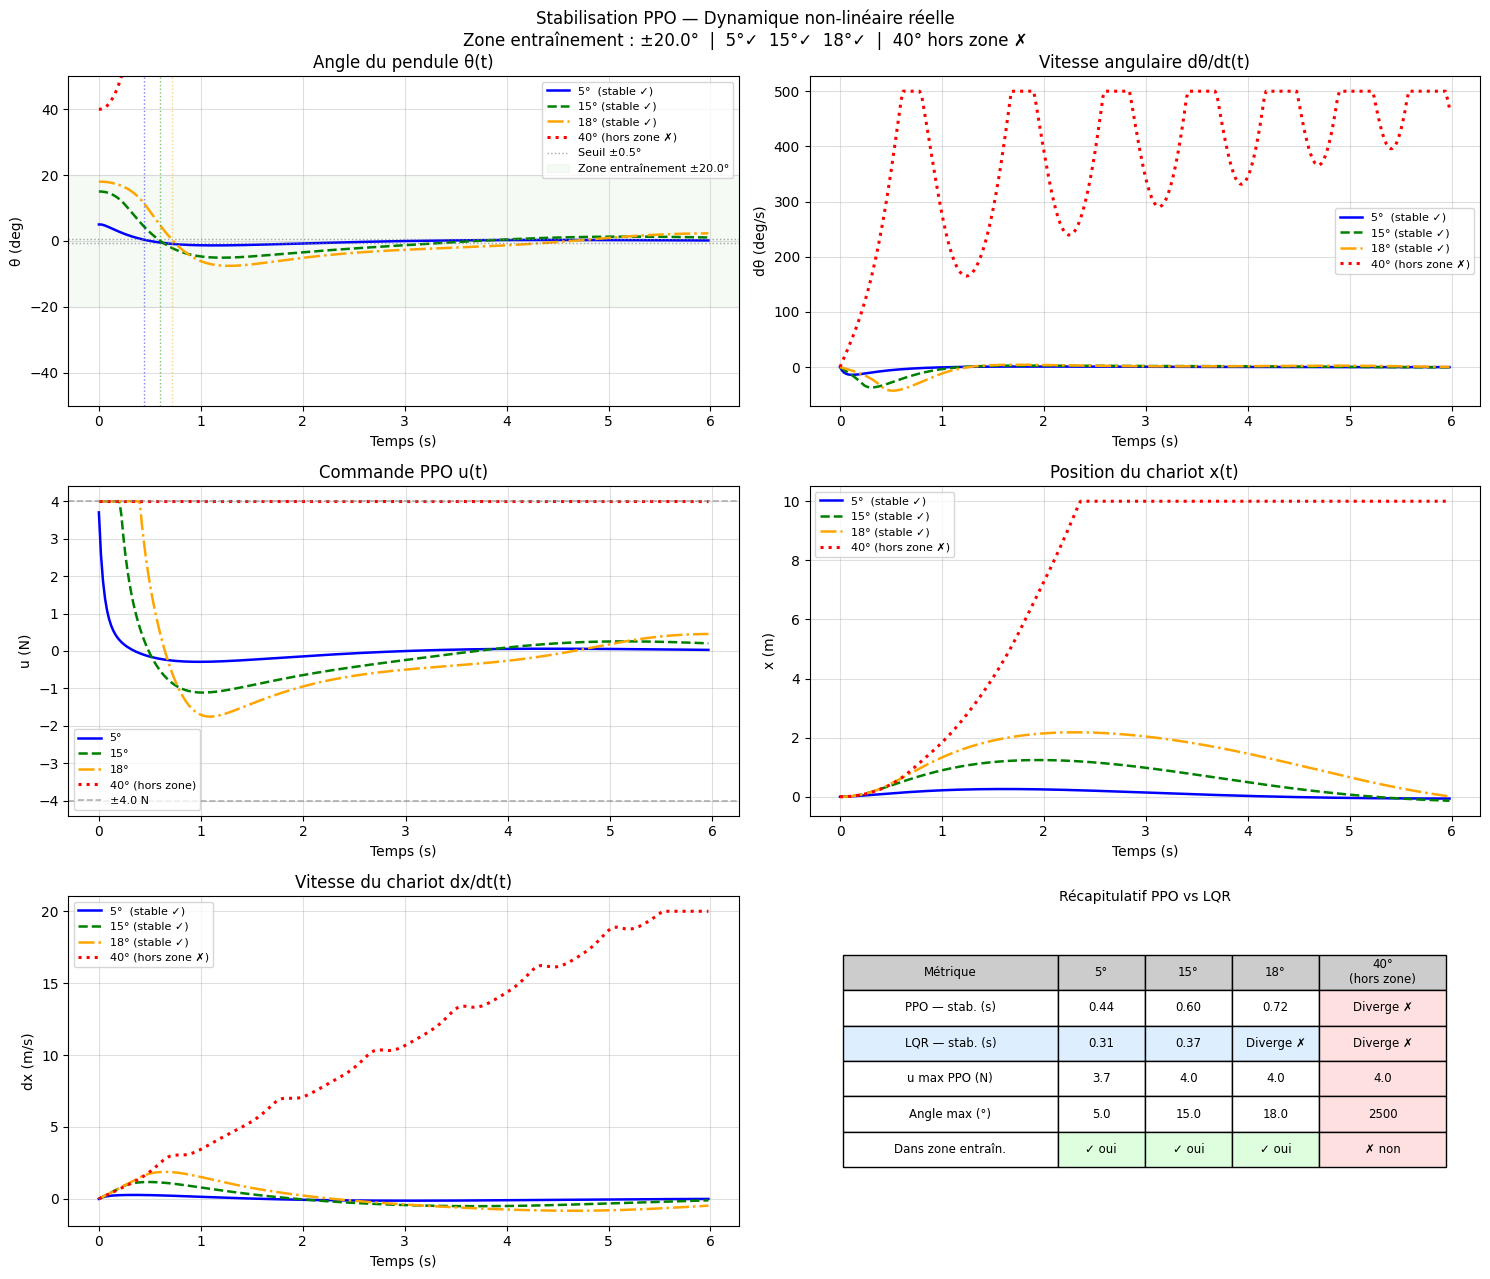


COMPARAISON PPO vs LQR
 Angle |  Zone train |    PPO (s) |    LQR (s) | Conclusion
----------------------------------------------------------------------
    5° |  OUI (±20°) |       0.44 |       0.31 | ✓ Les deux stabilisent
   15° |  OUI (±20°) |       0.60 |       0.37 | ✓ Les deux stabilisent
   18° |  OUI (±20°) |       0.72 |    Diverge | ★ PPO gagne sur LQR
 40.0° |         NON |    Diverge |    Diverge | ✗ Les deux divergent


In [5]:
"""
CODE 2 — STABILISATION AVEC LE MODÈLE PPO ENTRAÎNÉ

====================================================
Teste le modèle sur 4 angles initiaux :
  - θ₀ =  5°  → dans zone entraînement (±20°) → doit converger
  - θ₀ = 15°  → dans zone entraînement (±20°) → doit converger
  - θ₀ = 18°  → dans zone entraînement (±20°) → doit converger (là où LQR échouait)
  - θ₀ = 40°  → HORS zone entraînement        → doit diverger (limite de PPO)

Paramètres physiques identiques au code LQR.

Dépendances :
    pip install stable-baselines3 gymnasium matplotlib numpy
"""

import numpy as np
import matplotlib.pyplot as plt
from stable_baselines3 import PPO
import os

os.makedirs("figures", exist_ok=True)

print("="*60)
print("CODE 2 — STABILISATION PPO  (5°, 15°, 18°, 40°)")
print("="*60)
print("  5°, 15°, 18° : dans la zone d'entraînement (±20°) → convergent")
print("  40°           : HORS zone d'entraînement          → diverge")
print("="*60)

# =========================================================
# PARAMÈTRES PHYSIQUES — IDENTIQUES AU CODE LQR
# =========================================================
M  = 1.0      # masse chariot (kg)
m  = 0.1      # masse pendule (kg)
l  = 0.5      # longueur (m)
g  = 9.81     # gravité (m/s²)
dt = 0.02     # pas de temps (s)
T  = 6.0      # durée simulation (s)
t  = np.arange(0, T, dt)

U_MAX         = 4.0   # N — même que l'entraînement
ZONE_TRAIN    = 20.0   # degrés — frontière d'entraînement
ANGLE_HORS    = 40.0   # degrés — hors zone, pour montrer la limite

# =========================================================
# DYNAMIQUE NON-LINÉAIRE EXACTE (vos équations du mouvement)
# =========================================================
def step_dynamique(state, u):
    x, dx, theta, dtheta = state

    D    = l * (M + m * np.sin(theta)**2)
    rhs1 = u + m * l * dtheta**2 * np.sin(theta)

    ddx     = (l * rhs1 - m * l * np.cos(theta) * g * np.sin(theta)) / D
    ddtheta = ((M + m) * g * np.sin(theta) - np.cos(theta) * rhs1) / D

    return np.array([
        x      + dx      * dt,
        dx     + ddx     * dt,
        theta  + dtheta  * dt,
        dtheta + ddtheta * dt,
    ], dtype=np.float32)

# =========================================================
# CHARGEMENT DU MODÈLE PPO
# =========================================================
print("\nChargement du modèle PPO entraîné...")
try:
    model = PPO.load("models/ppo_pendule")
    print("Modèle chargé : models/ppo_pendule.zip")
except FileNotFoundError:
    print("ERREUR : modèle introuvable.")
    print("→ Lancez d'abord le Code 1 pour entraîner et sauvegarder le modèle.")
    exit(1)

# =========================================================
# BOUCLE DE SIMULATION PPO
# =========================================================
def simuler(theta0_deg, label=""):
    """
    Boucle fermée réelle :
      1. L'agent PPO observe l'état courant  s = [x, ẋ, θ, θ̇]
      2. Le réseau acteur choisit une action  u = π(s)
      3. La dynamique non-linéaire calcule le nouvel état
      4. On répète sur T secondes
    """
    state      = np.array([0., 0., theta0_deg * np.pi/180., 0.], dtype=np.float32)
    historique = [state.copy()]
    commandes  = []

    for _ in t[:-1]:
        action, _ = model.predict(state, deterministic=True)
        u = float(np.clip(action[0], -U_MAX, U_MAX))
        commandes.append(u)
        state = step_dynamique(state, u)
        historique.append(state.copy())

    print(f"  {label:5s} ({theta0_deg:4.0f}°) → angle max = "
          f"{np.max(np.abs(np.array(historique)[:,2]*180/np.pi)):.1f}°")
    return np.array(historique), np.array(commandes)

print("\nSimulations en cours...")
hist_5,  u_5  = simuler(5,            "5°")
hist_15, u_15 = simuler(15,           "15°")
hist_18, u_18 = simuler(18,           "18°")
hist_40, u_40 = simuler(ANGLE_HORS,   "40°")
print("Terminé.\n")

# =========================================================
# EXTRACTION DES VARIABLES
# =========================================================
def extraire(hist):
    return (hist[:,0],
            hist[:,1],
            hist[:,2] * 180/np.pi,
            hist[:,3] * 180/np.pi)

x_5,  dx_5,  th_5,  dth_5  = extraire(hist_5)
x_15, dx_15, th_15, dth_15 = extraire(hist_15)
x_18, dx_18, th_18, dth_18 = extraire(hist_18)
x_40, dx_40, th_40, dth_40 = extraire(hist_40)

# =========================================================
# TEMPS DE STABILISATION
# =========================================================
seuil = 0.5   # degrés

def t_stab(theta_deg):
    idx = np.where(np.abs(theta_deg) < seuil)[0]
    return float(t[idx[0]]) if len(idx) > 0 else np.nan

ts_5  = t_stab(th_5)
ts_15 = t_stab(th_15)
ts_18 = t_stab(th_18)
ts_40 = t_stab(th_40)

# =========================================================
# FIGURE PRINCIPALE — 4 angles, structure 3×2
# =========================================================
fig, axs = plt.subplots(3, 2, figsize=(15, 13))
fig.suptitle(
    "Stabilisation PPO — Dynamique non-linéaire réelle\n"
    f"Zone entraînement : ±{ZONE_TRAIN}°  |  "
    f"5°✓  15°✓  18°✓  |  40° hors zone ✗",
    fontsize=12
)

styles = {
    '5°' : ('b', '-',   1.8),
    '15°': ('g', '--',  1.8),
    '18°': ('orange', '-.', 1.8),
    '40°': ('r', ':',   2.2),
}

def plot4(ax, y5, y15, y18, y40, ylabel, title, clip_val=None):
    def c(y): return np.clip(y, -clip_val, clip_val) if clip_val else y
    ax.plot(t, c(y5),  'b-',        lw=1.8, label='5°  (stable ✓)')
    ax.plot(t, c(y15), 'g--',       lw=1.8, label='15° (stable ✓)')
    ax.plot(t, c(y18), color='orange', ls='-.', lw=1.8, label='18° (stable ✓)')
    ax.plot(t, c(y40), 'r:',        lw=2.2, label=f'40° (hors zone ✗)')
    ax.set_title(title)
    ax.set_xlabel('Temps (s)')
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.4)

# ---- 1. Angle ----
axs[0,0].plot(t, th_5,  'b-',        lw=1.8, label='5°  (stable ✓)')
axs[0,0].plot(t, th_15, 'g--',       lw=1.8, label='15° (stable ✓)')
axs[0,0].plot(t, np.clip(th_18,-45,45), color='orange', ls='-.', lw=1.8,
              label='18° (stable ✓)')
axs[0,0].plot(t, np.clip(th_40,-95,95), 'r:',  lw=2.2,
              label=f'40° (hors zone ✗)')
axs[0,0].axhline(y= seuil, color='gray', ls=':', lw=1, alpha=0.7,
                 label='Seuil ±0.5°')
axs[0,0].axhline(y=-seuil, color='gray', ls=':', lw=1, alpha=0.7)
axs[0,0].axhspan(-ZONE_TRAIN, ZONE_TRAIN, alpha=0.04, color='green',
                 label=f'Zone entraînement ±{ZONE_TRAIN}°')
for ts, c_ in [(ts_5,'b'),(ts_15,'g'),(ts_18,'orange')]:
    if not np.isnan(ts):
        axs[0,0].axvline(x=ts, color=c_, ls=':', lw=1, alpha=0.5)
axs[0,0].set_title('Angle du pendule θ(t)')
axs[0,0].set_xlabel('Temps (s)')
axs[0,0].set_ylabel('θ (deg)')
axs[0,0].set_ylim(-50, 50)
axs[0,0].legend(fontsize=8)
axs[0,0].grid(True, alpha=0.4)

# ---- 2. Vitesse angulaire ----
plot4(axs[0,1], dth_5, dth_15,
      np.clip(dth_18,-400,400), np.clip(dth_40,-500,500),
      'dθ (deg/s)', 'Vitesse angulaire dθ/dt(t)')

# ---- 3. Commande ----
axs[1,0].plot(t[:-1], u_5,  'b-',        lw=1.8, label='5°')
axs[1,0].plot(t[:-1], u_15, 'g--',       lw=1.8, label='15°')
axs[1,0].plot(t[:-1], u_18, color='orange', ls='-.', lw=1.8, label='18°')
axs[1,0].plot(t[:-1], u_40, 'r:',        lw=2.2,  label='40° (hors zone)')
axs[1,0].axhline(y= U_MAX, color='gray', ls='--', lw=1.2, alpha=0.6,
                 label=f'±{U_MAX} N')
axs[1,0].axhline(y=-U_MAX, color='gray', ls='--', lw=1.2, alpha=0.6)
axs[1,0].set_title('Commande PPO u(t)')
axs[1,0].set_xlabel('Temps (s)')
axs[1,0].set_ylabel('u (N)')
axs[1,0].legend(fontsize=8)
axs[1,0].grid(True, alpha=0.4)

# ---- 4. Position chariot ----
plot4(axs[1,1], x_5, x_15,
      np.clip(x_18,-5,5), np.clip(x_40,-10,10),
      'x (m)', 'Position du chariot x(t)')

# ---- 5. Vitesse chariot ----
plot4(axs[2,0], dx_5, dx_15,
      np.clip(dx_18,-15,15), np.clip(dx_40,-20,20),
      'dx (m/s)', 'Vitesse du chariot dx/dt(t)')

# ---- 6. Tableau récapitulatif ----
axs[2,1].axis('off')

def fmt(v):
    return f'{v:.2f}' if not np.isnan(v) else 'Diverge ✗'

# Valeurs LQR (U_MAX=4N) pour comparaison directe
lqr_stab = {5: '0.31', 15: '0.37', 18: 'Diverge ✗', 40: 'Diverge ✗'}

rows = [
    ['Métrique',              '5°',   '15°',  '18°',   f'40°\n(hors zone)'],
    ['PPO — stab. (s)',
     fmt(ts_5), fmt(ts_15), fmt(ts_18), fmt(ts_40)],
    ['LQR — stab. (s)',
     lqr_stab[5], lqr_stab[15], lqr_stab[18], lqr_stab[40]],
    ['u max PPO (N)',
     f'{np.max(np.abs(u_5)):.1f}',
     f'{np.max(np.abs(u_15)):.1f}',
     f'{np.max(np.abs(u_18)):.1f}',
     f'{np.max(np.abs(u_40)):.1f}'],
    ['Angle max (°)',
     f'{np.max(np.abs(th_5)):.1f}',
     f'{np.max(np.abs(th_15)):.1f}',
     f'{np.max(np.abs(th_18)):.1f}',
     f'{np.max(np.abs(th_40)):.0f}'],
    ['Dans zone entraîn.',
     '✓ oui', '✓ oui', '✓ oui', '✗ non'],
]

tbl = axs[2,1].table(cellText=rows, loc='center', cellLoc='center',
                     colWidths=[0.32, 0.13, 0.13, 0.13, 0.19])
tbl.auto_set_font_size(False)
tbl.set_fontsize(8.5)
tbl.scale(1.0, 1.9)

# Formatage du tableau
for col in range(5):
    tbl[(0, col)].set_facecolor('#cccccc')

# Ligne LQR en bleu clair
for col in range(5):
    tbl[(2, col)].set_facecolor('#ddeeff')

# Colonne 40° en rouge clair
for row in range(1, len(rows)):
    tbl[(row, 4)].set_facecolor('#ffe0e0')

# Ligne "dans zone" en vert/rouge
tbl[(5, 1)].set_facecolor('#ddffdd')
tbl[(5, 2)].set_facecolor('#ddffdd')
tbl[(5, 3)].set_facecolor('#ddffdd')
tbl[(5, 4)].set_facecolor('#ffe0e0')

axs[2,1].set_title('Récapitulatif PPO vs LQR', fontsize=10, y=0.96)

plt.tight_layout()
plt.savefig('figures/stabilisation_ppo_comparaison.png', dpi=300, bbox_inches='tight')
print("Figure sauvegardée : figures/stabilisation_ppo_comparaison.png")
plt.show()

# =========================================================
# RÉSUMÉ TERMINAL
# =========================================================
print("\n" + "="*60)
print("COMPARAISON PPO vs LQR")
print("="*60)
print(f"{'Angle':>6} | {'Zone train':>11} | {'PPO (s)':>10} | "
      f"{'LQR (s)':>10} | Conclusion")
print("-"*70)
data = [
    (5,          'OUI (±20°)', ts_5,  0.31),
    (15,         'OUI (±20°)', ts_15, 0.37),
    (18,         'OUI (±20°)', ts_18, float('nan')),
    (ANGLE_HORS, 'NON',        ts_40, float('nan')),
]
for deg, zone, ts_p, ts_l in data:
    ppo = f'{ts_p:.2f}' if not np.isnan(ts_p) else 'Diverge'
    lqr = f'{ts_l:.2f}' if not np.isnan(ts_l) else 'Diverge'
    if not np.isnan(ts_p) and np.isnan(ts_l):
        conc = '★ PPO gagne sur LQR'
    elif np.isnan(ts_p) and np.isnan(ts_l):
        conc = '✗ Les deux divergent'
    elif not np.isnan(ts_p):
        conc = '✓ Les deux stabilisent'
    else:
        conc = '✗ PPO diverge'
    print(f"{deg:>5}° | {zone:>11} | {ppo:>10} | {lqr:>10} | {conc}")
print("="*60)